# Cuaderno C · Extracción de las capas GAMC (Proyecto 05)

**MICROCLIMA · NASA Space Apps 2026 Cochabamba · Enfoque 2**

El portal solo permite descargar transporte y Red MÓNICA. Para salud, colegios, áreas verdes y población, el servidor entrega los atributos pero no la ubicación, así que la sacamos del mapa: detectamos cada punto en la imagen del servicio y consultamos sus datos (operación autorizada, solo lectura).

**Antes de empezar:**
1. Sube a este Colab `distritos_indicadores_ambientales_2024.geojson` (ícono de carpeta a la izquierda → subir).
2. Pega la clave del Proyecto 05 en la celda C0, donde dice `PEGAR_CLAVE_PROYECTO_05`.
3. **No subas a GitHub este cuaderno con la clave puesta**: bórrala antes de guardarlo en el repositorio.

## Celda C0 · Preparación

In [1]:
!pip install -q rasterio
import io, time, json, requests, numpy as np, pandas as pd, matplotlib.pyplot as plt
import geopandas as gpd, rasterio.features, rasterio.transform
from PIL import Image
from scipy import ndimage
from pyproj import Transformer

URL = 'https://serviciosgamc.cochabamba.bo/api/gs/wms'
KEY = 'aadad'
SID = {'areas_equipamiento': '97a589fe-595e-45dd-91d4-38524877f1ed',
       'centros_salud': 'e40fa280-f649-4614-9526-1b3dcce596b3',
       'unidades_educativas': '7655ba3d-5d9e-44ff-bf65-26f81f83d7ec',
       'poblacion_manzanas': '194a02a0-a73a-48c1-a260-82847c5c905d',
       'areas_verdes': '47360ddc-e35f-4ece-a995-59e90eb79cc6'}

t = Transformer.from_crs(4326, 3857, always_xy=True)
x0, y0 = t.transform(-66.2529, -17.5054); x1, y1 = t.transform(-66.0844, -17.2716)
CIUDAD = (x0, y0, x1, y1)

dist = gpd.read_file('/content/distritos_indicadores_ambientales_2024.geojson')[['codigo_distrito', 'nombre', 'geometry']].to_crs(3857)
dist['codigo_distrito'] = dist['codigo_distrito'].astype(int)

def consulta(sid, bbox, fc=5000):
    p = dict(key=KEY, service_id=sid, SERVICE='WMS', VERSION='1.1.1', REQUEST='GetFeatureInfo', LAYERS='',
             QUERY_LAYERS='', SRS='EPSG:3857', BBOX=','.join(map(str, bbox)), WIDTH='1', HEIGHT='1', X='0', Y='0',
             INFO_FORMAT='application/json', FEATURE_COUNT=str(fc))
    r = requests.get(URL, params=p, timeout=180); r.raise_for_status(); return r.json()

def getmap(sid, bb, w, h):
    p = dict(key=KEY, service_id=sid, SERVICE='WMS', VERSION='1.1.1', REQUEST='GetMap', LAYERS='',
             FORMAT='image/png', TRANSPARENT='true', SRS='EPSG:3857', BBOX=','.join(map(str, bb)), WIDTH=str(w), HEIGHT=str(h))
    r = requests.get(URL, params=p, timeout=180); r.raise_for_status()
    return np.array(Image.open(io.BytesIO(r.content)).convert('RGBA'))

def mosaico(sid, n=3, px=1600):
    """Imagen de toda la ciudad en alta resolución, armada con n x n partes."""
    th = int(px * (y1 - y0) / (x1 - x0)); W, H = px * n, th * n
    out = np.zeros((H, W, 4), np.uint8); dx, dy = (x1 - x0) / n, (y1 - y0) / n
    for i in range(n):
        for j in range(n):
            bb = (x0 + i * dx, y1 - (j + 1) * dy, x0 + (i + 1) * dx, y1 - j * dy)
            out[j * th:(j + 1) * th, i * px:(i + 1) * px] = getmap(sid, bb, px, th)
    return out, rasterio.transform.from_bounds(x0, y0, x1, y1, W, H)

print('Listo. Distritos cargados:', len(dist))

Listo. Distritos cargados: 15


## Celda C1 · Población por distrito

**Revisa el total:** si sale cerca de 632 mil, es el Censo 2012; si sale bastante más, probablemente el Censo 2024. Anótalo: se usa en el cuaderno D (`ANIO_CENSO`).

In [4]:
pob = pd.DataFrame([f['properties'] for f in consulta(SID['poblacion_manzanas'], CIUDAD, fc=100000)['features']])
pob.columns = pob.columns.str.strip().str.lower()
print('Columnas:', pob.columns.tolist())

pob = pob[pob['municipio'].astype(str).str.strip().str.lower() == 'cochabamba'].copy()
for c in ['personas', 'viviendas']:
    pob[c] = pd.to_numeric(pob[c], errors='coerce')
pob['codigo_distrito'] = pob['distritos'].astype(str).str.extract(r'(\d+)')[0].astype(int)
pob_d = pob.groupby('codigo_distrito')[['personas', 'viviendas']].sum()
print(pob_d, '\nTotal habitantes:', int(pob_d['personas'].sum()))

Columnas: ['departamento', 'provincia', 'nombre', 'municipio', 'personas', 'viviendas', 'distritos', 'sup', 'densidad']
                 personas  viviendas
codigo_distrito                     
1                    6536       2367
2                   46863      16376
3                   51921      20353
4                   39526      13708
5                   36779      12803
6                   22391       8614
7                    5016       1725
8                   15618       5728
9                   57651      20631
10                  29599      13816
11                  14590       7388
12                  48286      24301
13                   9025       3100
14                   7904       2765
15                   9573       4219 
Total habitantes: 401278


## Celda C2 · Ubicar centros de salud y colegios

Es la celda más lenta (consulta cada punto). **Revisa:** deberían salir cerca de 67 establecimientos y 264 colegios. Si salen bastante menos, hay puntos pegados: cambia `n=3` por `n=5` en `mosaico` (celda C0), vuelve a correr C0 y luego esta.

In [6]:
def ubicar_puntos(nombre, campo_id):
    a, tr = mosaico(SID[nombre])
    lab, n = ndimage.label(a[..., 3] > 40)
    filas = []
    for k, sl in enumerate(ndimage.find_objects(lab), start=1):
        ys, xs = np.nonzero(lab[sl] == k)
        X, Y = rasterio.transform.xy(tr, ys.mean() + sl[0].start, xs.mean() + sl[1].start)
        xa, ya = rasterio.transform.xy(tr, sl[0].stop, sl[1].start)
        xb, yb = rasterio.transform.xy(tr, sl[0].start, sl[1].stop)
        for f in consulta(SID[nombre], (xa, ya, xb, yb), fc=20)['features'] or [{'properties': {}}]:
            filas.append({**f['properties'], 'x': X, 'y': Y})
        time.sleep(0.05)
    df = pd.DataFrame(filas)
    # Si el campo cambió de nombre (mayúsculas u otro nombre), lo detecta y lo renombra
    if campo_id not in df.columns:
        print('Columnas recibidas:', df.columns.tolist())
        cand = [c for c in df.columns if c.strip().lower() in (campo_id.lower(), 'name', 'nombre')]
        df = df.rename(columns={cand[0]: campo_id})
    df = pd.concat([df[df[campo_id].notna()].drop_duplicates(subset=[campo_id]), df[df[campo_id].isna()]])
    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.x, df.y), crs=3857)
    gdf = gpd.sjoin(gdf, dist[['codigo_distrito', 'geometry']], predicate='within', how='left').drop(columns='index_right')
    print(f'{nombre}: {n} puntos en el mapa | {gdf[campo_id].notna().sum()} con nombre | fuera de distritos: {gdf["codigo_distrito"].isna().sum()}')
    return gdf

colegios = ubicar_puntos('unidades_educativas', 'name')
print(salud['Nivel'].value_counts(dropna=False))

Columnas recibidas: ['Nombre', 'x', 'y']
unidades_educativas: 136 puntos en el mapa | 253 con nombre | fuera de distritos: 1
Nivel
1er nivel          44
3er nivel           8
2do nivel           5
None                5
Vacunatorio         2
CCESD               1
1er. Nivel          1
Banco de Sangre     1
Name: count, dtype: int64


## Celda C3 · Superficie de áreas verdes por distrito

In [7]:
a, tr = mosaico(SID['areas_verdes'])
mask = a[..., 3] > 40
ras = rasterio.features.rasterize(zip(dist.geometry, dist.codigo_distrito), out_shape=mask.shape,
                                  transform=tr, fill=0, dtype='int32')
m2_por_pixel = abs(tr.a * tr.e) * np.cos(np.radians(17.4)) ** 2   # corrige la deformación del mapa web
verde_d = (pd.Series(ras[mask & (ras > 0)]).value_counts() * m2_por_pixel).rename('area_verde_m2')
print((verde_d / 1e4).round(1).rename('hectáreas'))

9     359.8
8     207.0
15    128.0
2      89.2
4      87.1
12     80.7
5      73.9
14     59.1
3      54.5
1      54.0
6      52.7
10     51.0
11     32.6
7      30.2
13      5.4
Name: hectáreas, dtype: float64


## Celda C4 · Áreas de equipamiento (terrenos municipales)

2009 terrenos de equipamiento detectados


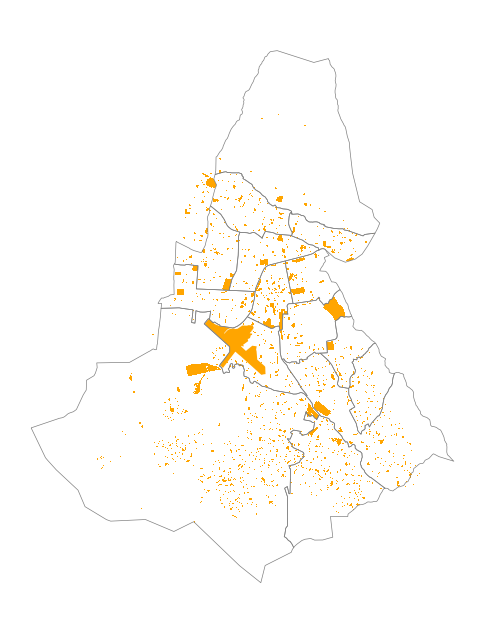

In [9]:
from rasterio.features import shapes
from shapely.geometry import shape

a, tr = mosaico(SID['areas_equipamiento'])
mask = ndimage.binary_fill_holes(a[..., 3] > 40)          # rellena por si la capa solo dibuja bordes
polys = [shape(g) for g, v in shapes(mask.astype('uint8'), mask=mask, transform=tr) if v == 1]
eq = gpd.GeoDataFrame(geometry=polys, crs=3857)
eq = eq[eq.area > 200].reset_index(drop=True)            # quita manchitas sueltas
eq['area_m2'] = (eq.area * np.cos(np.radians(17.4)) ** 2).round(0)   # corrige la deformación del mapa web
print(len(eq), 'terrenos de equipamiento detectados')

# Vista rápida para revisar
fig, ax = plt.subplots(figsize=(6, 8))
dist.boundary.plot(ax=ax, color='gray', linewidth=0.5)
eq.plot(ax=ax, color='orange')
ax.set_axis_off(); plt.show()

## Celda C5 · Juntar, guardar y revisar

Al terminar, descarga (ícono de carpeta → clic derecho → Descargar):
- `indicadores_gamc_distritos.csv` y `areas_equipamiento.geojson` → `data/gamc_vectores/`
- `equipamientos.geojson` y `areas_equipamiento.geojson` → `public/data/`

**No cierres este Colab:** el cuaderno D usa estas variables.

                      nombre  personas  viviendas  area_verde_m2  \
codigo_distrito                                                    
1.0               Distrito 1      9743       3552   5.404270e+05   
2.0               Distrito 2     45026      15710   8.919501e+05   
3.0               Distrito 3     44049      17266   5.448357e+05   
4.0               Distrito 4     32597      11211   8.705049e+05   
5.0               Distrito 5     25421       8751   7.392192e+05   
6.0               Distrito 6     19128       7454   5.265197e+05   
7.0               Distrito 7      9972       3431   3.016373e+05   
8.0               Distrito 8     29597      11074   2.069502e+06   
9.0               Distrito 9     81815      30203   3.598258e+06   
10.0             Distrito 10     17120       9186   5.104705e+05   
11.0             Distrito 11     15185       7045   3.258083e+05   
12.0             Distrito 12     42283      22304   8.071568e+05   
13.0             Distrito 13     11393       385

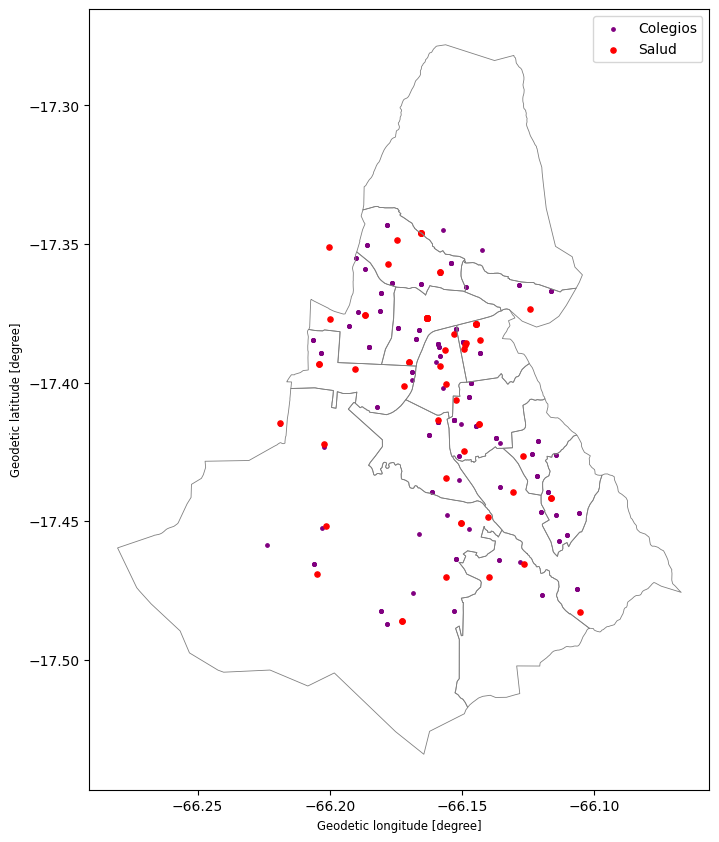

In [13]:
ind = dist[['codigo_distrito', 'nombre']].set_index('codigo_distrito').join(pob_d).join(verde_d)
ind = ind.join(salud.groupby(['codigo_distrito', 'Nivel']).size().unstack(fill_value=0).add_prefix('salud_'))
ind = ind.join(colegios.groupby('codigo_distrito').size().rename('colegios')).fillna(0)
print(ind.sort_index())
ind.to_csv('indicadores_gamc_distritos.csv')

equip = pd.concat([
    salud.assign(tipo='salud', nombre_eq=salud['Establecimiento'], nivel=salud['Nivel'])[['tipo', 'nombre_eq', 'nivel', 'codigo_distrito', 'geometry']],
    colegios.assign(tipo='educacion', nombre_eq=colegios['name'], nivel=None)[['tipo', 'nombre_eq', 'nivel', 'codigo_distrito', 'geometry']]])
gpd.GeoDataFrame(equip, crs=3857).to_crs(4326).rename(columns={'nombre_eq': 'nombre'}).to_file('equipamientos.geojson', driver='GeoJSON')
eq.to_crs(4326).to_file('areas_equipamiento.geojson', driver='GeoJSON')

ax = dist.to_crs(4326).boundary.plot(figsize=(8, 11), color='gray', linewidth=0.6)
colegios.to_crs(4326).plot(ax=ax, color='purple', markersize=6, label='Colegios')
salud.to_crs(4326).plot(ax=ax, color='red', markersize=14, label='Salud')
plt.legend(); plt.show()

In [11]:
def manzanas(bb, nivel=0):
    fs = consulta(SID['poblacion_manzanas'], bb, fc=100000)['features']
    if len(fs) >= 1000 and nivel < 4:          # demasiadas: dividir en 4 y volver a pedir
        xa, ya, xb, yb = bb; xm, ym = (xa + xb) / 2, (ya + yb) / 2
        return sum((manzanas(b, nivel + 1) for b in
                    [(xa, ya, xm, ym), (xm, ya, xb, ym), (xa, ym, xm, yb), (xm, ym, xb, yb)]), [])
    return fs

todas = manzanas(CIUDAD)
unicas = {tuple(sorted(f['properties'].items())) for f in todas}
pob = pd.DataFrame([dict(u) for u in unicas])
pob.columns = pob.columns.str.strip().str.lower()
print('Manzanas recibidas:', len(todas), '| distintas:', len(pob))

pob = pob[pob['municipio'].astype(str).str.strip().str.lower() == 'cochabamba'].copy()
for c in ['personas', 'viviendas']:
    pob[c] = pd.to_numeric(pob[c], errors='coerce')
pob['codigo_distrito'] = pob['distritos'].astype(str).str.extract(r'(\d+)')[0].astype(int)
pob_d = pob.groupby('codigo_distrito')[['personas', 'viviendas']].sum()
print(pob_d, '\nTotal habitantes:', int(pob_d['personas'].sum()))

Manzanas recibidas: 227021 | distintas: 8198
                 personas  viviendas
codigo_distrito                     
1                    9743       3552
2                   45026      15710
3                   44049      17266
4                   32597      11211
5                   25421       8751
6                   19128       7454
7                    9972       3431
8                   29597      11074
9                   81815      30203
10                  17120       9186
11                  15185       7045
12                  42283      22304
13                  11393       3856
14                  14576       5371
15                  17692       7562 
Total habitantes: 415597
